In [1]:
import os
import sys

In [2]:
from gradix import Tensor
from gradix.utils import visualize_computation_graph

In [3]:

left = Tensor([1.0, 2.0, 3.0], requires_grad=True, name="left input")
right = Tensor([4.0, 5.0, 6.0], requires_grad=True, name="right input")

result = (left * right).sum()
result.backward()

print(result.data)  # 32.0
print(left.grad)    # [4. 5. 6.]
print(right.grad)   # [1. 2. 3.]

32.0
[4. 5. 6.]
[1. 2. 3.]


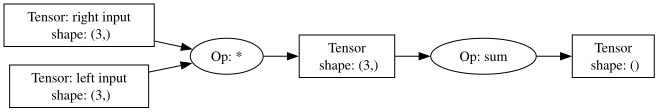

In [4]:
visualize_computation_graph(result)

In [3]:
t = Tensor([1, 2], requires_grad = False)
t

Tensor([1. 2.], dtype: float32, Shape: [2])

In [4]:
import numpy as np

In [5]:
t = Tensor(np.random.randn(2, 3, 4, 5), requires_grad = True)
t

Tensor([[[[ 1.70053745e+00  1.28513868e-01  1.26081632e-01  2.12277838e-01
    -2.61155917e-01]
   [ 4.17082272e-01 -8.00880925e-01  4.34861047e-01  1.04017028e+00
    -9.82701956e-02]
   [-1.23957926e+00 -3.86108840e-01 -6.26872113e-01 -4.74241114e-02
    -2.60441046e-01]
   [ 4.64089060e-01  9.95838639e-01 -3.61652975e-01  5.96259087e-01
    -4.61149859e-02]]

  [[ 9.58110819e-03 -8.91005616e-01  1.16776488e+00  2.99812599e-02
    -3.89886219e-01]
   [-1.89695155e+00 -1.67221367e-01 -2.69017132e-01  7.28516219e-01
    -2.03119014e-01]
   [ 8.48137944e-01  1.53720334e+00  1.07075898e+00  2.67490958e-01
     3.32162550e-01]
   [ 1.62718007e+00 -5.84778587e-01  9.08904535e-01  9.22796333e-01
    -6.04457029e-01]]

  [[ 7.10661074e-01 -4.72911480e-01  1.10167758e+00  1.37704329e+00
    -1.89634686e+00]
   [-1.72938421e+00  2.99285498e-01  1.49163998e+00 -2.13155211e+00
     5.18760829e-02]
   [-6.59768894e-01 -1.27265401e+00  8.08978152e-01 -7.75514233e-01
     2.82705144e-02]
   [ 2.227

In [7]:
a = Tensor(1, requires_grad = True, name = 'a')
b = Tensor(2, requires_grad = True, name = 'b')
c = Tensor(3, requires_grad = True, name = 'c')
d = Tensor(4, requires_grad = True, name = 'd')
a, b, c, d

(Tensor(1.0, dtype: float32, Shape: []),
 Tensor(2.0, dtype: float32, Shape: []),
 Tensor(3.0, dtype: float32, Shape: []),
 Tensor(4.0, dtype: float32, Shape: []))

In [8]:
e = a + b
e.name = 'e'
f = e * d
f.name = 'f'
g = c * e
g.name = 'g'
h = f + g
h.name = 'h'
i = h * g + f * e + e * h
i.name = 'i'
i

Tensor(288.0, dtype: float32, Shape: [])

In [12]:
%conda install graphviz


Note: you may need to restart the kernel to use updated packages.



InvalidMatchSpec: Invalid spec 'Student\anaconda3\envs\ml': Invalid spec 'Student\anaconda3\envs\ml': package name contains invalid characters (\)



In [10]:
i.backward()

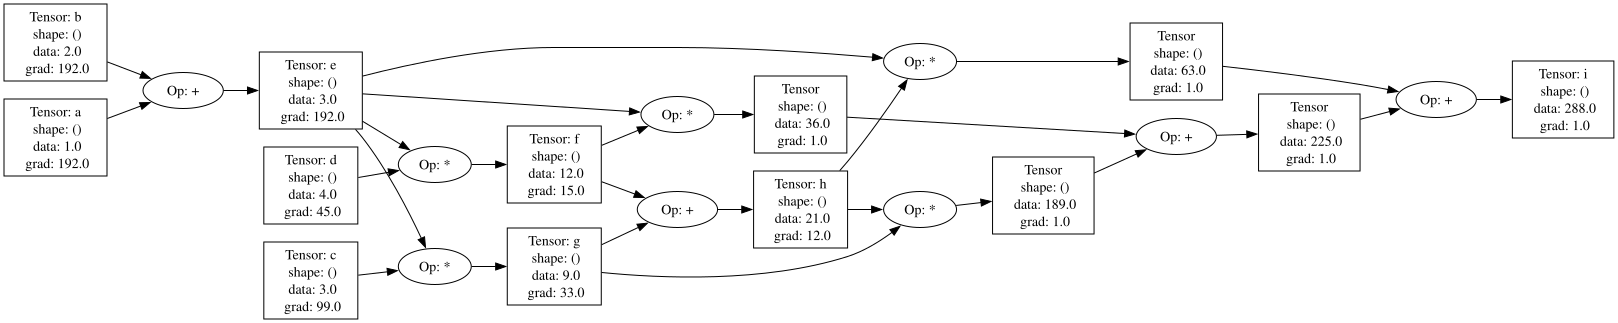

In [11]:
visualize_computation_graph(i, c_view_options = ['data', 'grad'])